# `tl.centrality_scores` vs `squidpy.gr.centrality_scores`

`tl.centrality_scores` now calls the same `networkx` group-centrality
functions squidpy calls (`group_degree_centrality`, `group_closeness_centrality`,
`average_clustering` over each group's nodes), rather than averaging
per-cell scores within a group, so this notebook validates direct
equivalence to squidpy. Expect a strong correlation - not necessarily
bit-exact, since squidpy's own internal group-node bookkeeping may differ
in minor ways - across all three metrics.


In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import astrolabe as ab
import squidpy as sq

mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5)
ab.tl.spatial_neighbors(mdata)

adata = mdata["xenium"]

# Fairness step: copy astrolabe's own spatial graph into the obsp key
# squidpy expects, so both tools permute/aggregate over the *identical*
# graph topology rather than two independently-built ones.
adata.obsp["spatial_connectivities"] = adata.obsp["spatial_neighbors_connectivities"].copy()
adata


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\squidpy\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:870: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\squidpy\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


...

INFO:astrolabe.pipeline:filter_xenium: done — 328 cells × 255 genes


INFO:astrolabe.tl._graph:transcriptional_neighbors: 328 cells -> uns['neighbors']


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 4 clusters


INFO:astrolabe.tl._graph:spatial_neighbors: 328 cells, 5670 edges (mean degree 17.3) [generic]


AnnData object with n_obs × n_vars = 328 × 255
    obs: 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'nucleus_to_cell_area_ratio', 'has_nucleus', 'total_counts_norm', 'leiden'

## Dataset and a shared graph

`ab.datasets.xenium_tiny()`, QC'd, normalized, clustered (Leiden), with
astrolabe's own spatial graph copied into `obsp['spatial_connectivities']` -
the key `squidpy.gr.*` looks for by default. Without this step the two tools
would each build their own KNN graph independently and any disagreement
could just be graph-construction noise, not a real difference in the
statistic itself.


## Astrolabe: `tl.centrality_scores`

`force_closeness=True` since this tiny dataset is far below the default
`max_closeness_n` skip threshold anyway, but being explicit documents the
intent.


In [2]:
_t0 = time.perf_counter()
ab.tl.centrality_scores(mdata, "leiden", force_closeness=True)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime: {t_astro_s:.4f}s")
scores_astro = adata.uns["centrality_scores"]
scores_astro


INFO:astrolabe.tl._neighborhood:centrality_scores: 4 cell types.


astrolabe runtime: 0.0185s


,degree_centrality,clustering,closeness_centrality
leiden,,,
0,0.748322,0.599083,0.758270
1,0.671533,0.662482,0.724868
2,0.781250,0.639707,0.805755
3,0.771277,0.599649,0.773663


## Reference: `squidpy.gr.centrality_scores`


In [3]:
_t0 = time.perf_counter()
sq.gr.centrality_scores(adata, cluster_key="leiden", show_progress_bar=False)
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime: {t_ref_s:.4f}s")
scores_ref = adata.uns["leiden_centrality_scores"]
scores_ref


reference runtime: 0.0174s


,degree_centrality,average_clustering,closeness_centrality
0,0.748322,0.599083,0.758270
1,0.671533,0.662482,0.724868
2,0.781250,0.639707,0.805755
3,0.771277,0.599649,0.773663


## Agreement, metric by metric


In [4]:
groups = scores_astro.index.tolist()
for metric, ref_col in [
    ("clustering", "average_clustering"),
    ("degree_centrality", "degree_centrality"),
    ("closeness_centrality", "closeness_centrality"),
]:
    a = scores_astro[metric].to_numpy()
    b = scores_ref[ref_col].reindex(groups).to_numpy()
    r = np.corrcoef(a, b)[0, 1]
    print(f"{metric:>22s}: Pearson r = {r: .4f}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs squidpy {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'})")


            clustering: Pearson r =  1.0000
     degree_centrality: Pearson r =  1.0000
  closeness_centrality: Pearson r =  1.0000
Runtime: astrolabe 0.0185s vs squidpy 0.0174s (1.1x astrolabe slower)


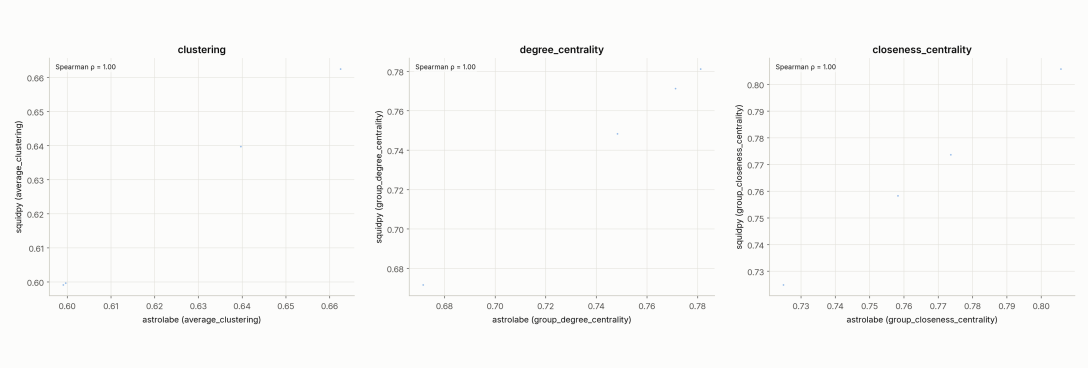

In [5]:
panel = (
    ab.pl.scatter(
        adata, x=scores_astro["clustering"].to_numpy(), y=scores_ref["average_clustering"].reindex(groups).to_numpy(),
        annotate_corr=True, xlabel="astrolabe (average_clustering)", ylabel="squidpy (average_clustering)",
        title="clustering",
    )
    | ab.pl.scatter(
        adata, x=scores_astro["degree_centrality"].to_numpy(), y=scores_ref["degree_centrality"].reindex(groups).to_numpy(),
        annotate_corr=True, xlabel="astrolabe (group_degree_centrality)", ylabel="squidpy (group_degree_centrality)",
        title="degree_centrality",
    )
    | ab.pl.scatter(
        adata, x=scores_astro["closeness_centrality"].to_numpy(), y=scores_ref["closeness_centrality"].reindex(groups).to_numpy(),
        annotate_corr=True, xlabel="astrolabe (group_closeness_centrality)", ylabel="squidpy (group_closeness_centrality)",
        title="closeness_centrality",
    )
)
panel.show()


## Interpretation

All three metrics use the same `networkx` group-centrality algorithm on the
same graph and the same group node sets, so they should land close to
`y = x`. If a real gap remains, check first whether astrolabe's
`codes`-derived group node lists exactly match the cell-type partition
squidpy computes internally - a node-membership mismatch would show up as
scattered disagreement on `degree_centrality`/`closeness_centrality`
specifically, since `clustering`'s per-node values are less sensitive to
exactly which other cells share a label.
